<img src="https://www.nvidia.com/content/dam/en-zz/Solutions/about-nvidia/logo-and-brand/01-nvidia-logo-vert-500x200-2c50-d.png" width="160">

# Caja Clara · Asistente ajustado con LoRA
### Hackathon NVIDIA Oaxaca 2026 · Economía Digital

El asistente convierte lo que dice la persona (por voz o texto) en **una acción JSON** que la app ejecuta: *"dame dos la yudas y una orchata"* → `{"accion": "agregar", "productos": [{"producto": "tlayuda", "cantidad": 2}, {"producto": "agua_horchata", "cantidad": 1}]}`.
**El modelo propone, el código valida y calcula, la persona confirma.**

## Objetivos
1. Describir el modelo base y el objetivo del asistente (bases, sección 8).
2. Presentar los datos sintéticos de entrenamiento, su división y los casos reservados.
3. Mostrar el ajuste fino con **LoRA** en la GPU del concurso (Tesla T4) y su registro.
4. Comparar **modelo base vs. modelo ajustado** en las mismas condiciones, más una referencia con un modelo de NVIDIA de 8B.
5. Analizar errores y limitaciones con honestidad (bases, sección 13).

## Contenido
1. Planificación y selección · 2. Datos · 3. Entrenamiento LoRA · 4. Evaluación comparativa · 5. Errores y límites · 6. Integración · 7. Declaración de IA

## 1. Planificación y selección
| Campo | Valor |
|---|---|
| Modelo base | **Qwen2.5-1.5B-Instruct** (Alibaba, licencia Apache 2.0), descargado de Hugging Face |
| Técnica | Ajuste fino supervisado con **LoRA** (rango 16, alpha 32, capas de atención y MLP) |
| Objetivo | Convertir frases de venta de micronegocios (comida, tienda, materiales) en 9 acciones JSON; pedir aclaración si falta información; rechazar lo fuera de alcance; pedir confirmación antes de borrar |
| ¿Por qué 1.5B? | Entrena en una T4 (16 GB) y corre en la laptop de la demo (RTX 2060, 6 GB) sin internet |
| Referencia NVIDIA | **Nemotron 3.5 Bolt E4B** (8B) por API de NVIDIA NIM, solo con prompt (sin ajuste) |

In [1]:
import json, collections, matplotlib.pyplot as plt, numpy as np
%matplotlib inline
cfg = json.load(open("resultados_asistente/config_entrenamiento.json"))
print(json.dumps(cfg, indent=1, ensure_ascii=False))

{
 "modelo": "Qwen/Qwen2.5-1.5B-Instruct",
 "datos": "datos_asistente",
 "salida": "resultados_asistente",
 "epocas": 3,
 "lr": 0.0002,
 "rango": 16,
 "max_len": 384,
 "n_test": 60,
 "entrenar": true,
 "evaluar": true,
 "gpu": "Tesla T4",
 "duracion_s": 917,
 "pasos": 219,
 "train_loss_final": 0.03004779250969149
}


## 2. Datos (sintéticos, revisados)
Las frases se generan con plantillas y el catálogo de los tres giros. Para medir si el modelo **generaliza**, validación y prueba usan **plantillas que no aparecen en entrenamiento**. Una parte de las frases (cerca del 5% en entrenamiento) trae **errores típicos del dictado por voz** ("la yudas", "bariyas", "koka") con la etiqueta correcta, para que el modelo aprenda a normalizarlos.

Los **14 casos reservados** se escribieron a mano y **nunca** se usaron para entrenar (bases, sección 13).

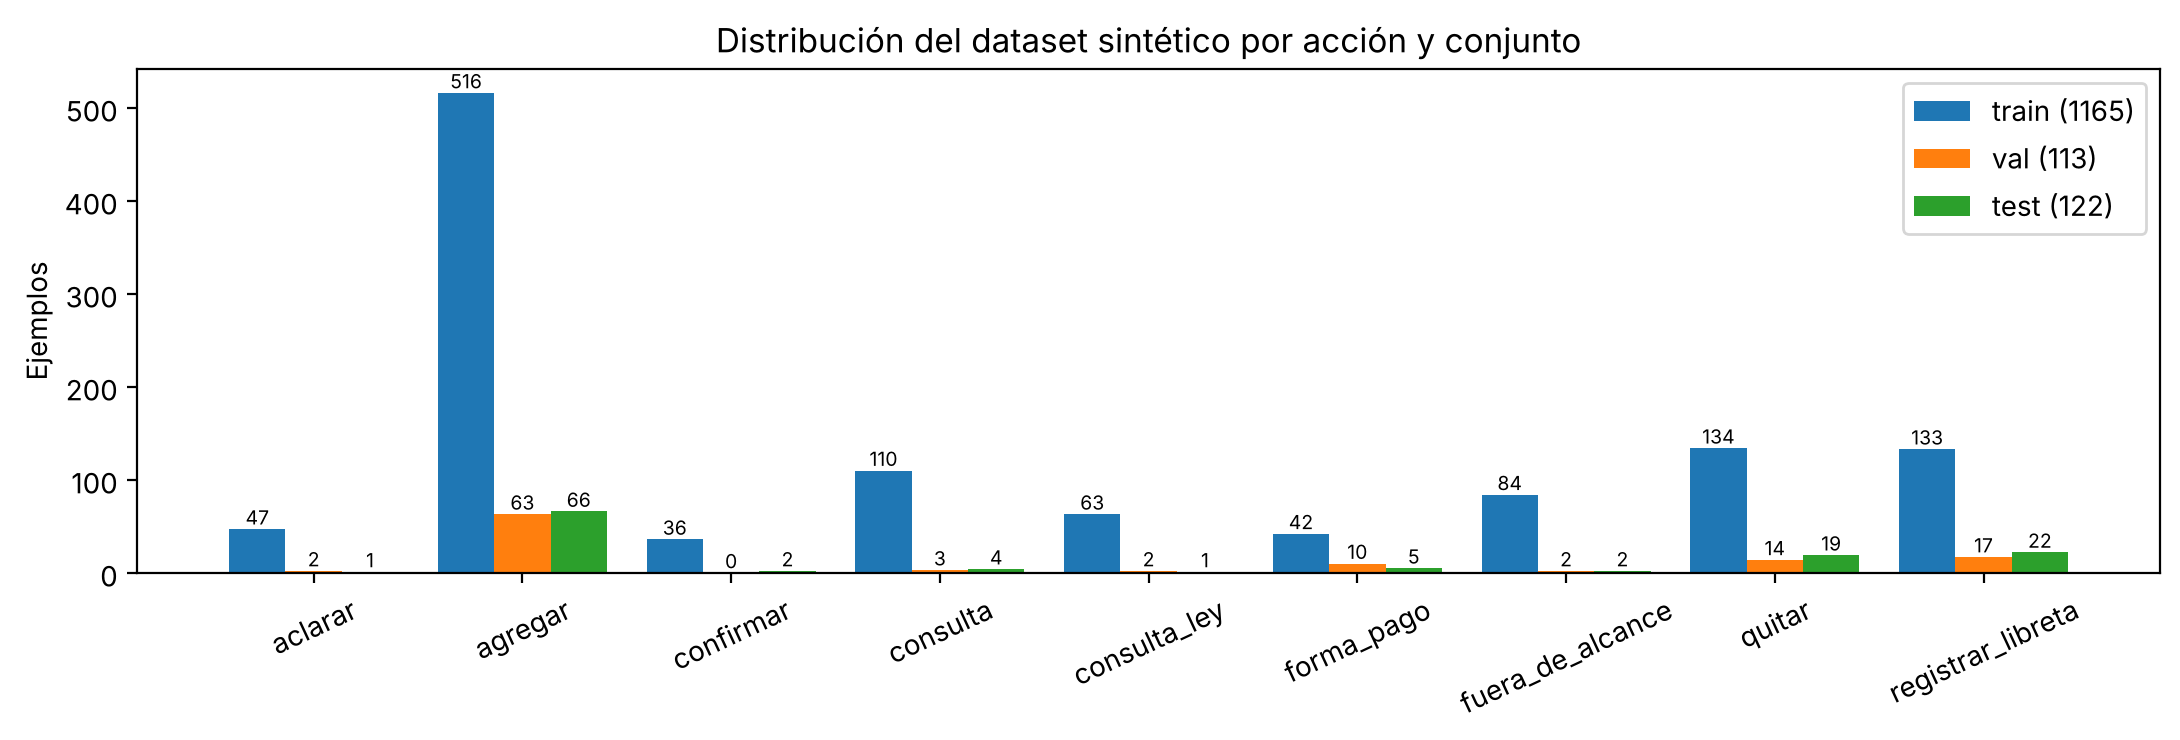

Casos reservados: 14


In [2]:
resumen = json.load(open("datos_asistente/resumen.json"))
acciones = sorted({a for s in ("train","val","test") for a in resumen[s]["por_accion"]})
fig, ax = plt.subplots(figsize=(11, 3.8)); x = np.arange(len(acciones)); w = .27
for i, s in enumerate(["train", "val", "test"]):
    v = [resumen[s]["por_accion"].get(a, 0) for a in acciones]
    b = ax.bar(x + (i-1)*w, v, w, label=f"{s} ({resumen[s]['ejemplos']})"); ax.bar_label(b, fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(acciones, rotation=25); ax.set_ylabel("Ejemplos")
ax.set_title("Distribución del dataset sintético por acción y conjunto"); ax.legend(); plt.tight_layout(); plt.show()
print("Casos reservados:", resumen["casos_reservados"])

In [3]:
ejemplos = [json.loads(l) for l in open("datos_asistente/train.jsonl")]
dictado = [e for e in ejemplos if any(w in e["messages"][1]["content"] for w in ["la yuda","bariya","koka","semento","torniyo","esquitles","eskitels","choquis","ganzito"])]
print(f"Ejemplos de entrenamiento: {len(ejemplos)} | con errores de dictado: {len(dictado)}\n")
for e in dictado[:5] + ejemplos[:3]:
    print(f"  {e['messages'][1]['content']!r:55s} -> {e['messages'][2]['content'][:85]}")
print("\nCasos reservados:")
for l in open("datos_asistente/casos_reservados.jsonl"):
    c = json.loads(l); print(f"  [{c['categoria']:20s}] {c['frase']}")

Ejemplos de entrenamiento: 1165 | con errores de dictado: 51

  'quítale media docena de torniyos'                      -> {"accion": "quitar", "productos": [{"producto": "tornillo", "cantidad": 6}]}
  'borra dos koka-cola'                                   -> {"accion": "quitar", "productos": [{"producto": "coca_cola", "cantidad": 2}]}
  'ponme 2 kokas'                                         -> {"accion": "agregar", "productos": [{"producto": "coca_cola", "cantidad": 2}]}
  'borra 3 koka-cola'                                     -> {"accion": "quitar", "productos": [{"producto": "coca_cola", "cantidad": 3}]}
  'en la libreta tengo 1 esquitles de ayer'               -> {"accion": "registrar_libreta", "productos": [{"producto": "skittles", "cantidad": 1}
  '¿quién ganó el partido?'                               -> {"accion": "fuera_de_alcance", "respuesta": "Solo puedo ayudarte con tus ventas, cobr
  'ponme 1 tlayuda y cinco café de olla'                  -> {"accion": "agregar", "prod

## 3. Entrenamiento LoRA en la GPU del concurso
LoRA **congela** el modelo original y entrena solo unas matrices pequeñas añadidas a sus capas. La pérdida se calcula **solo sobre la respuesta JSON**, no sobre el prompt.

In [4]:
print(open("resultados_asistente/entrenamiento_lora.log").read().split("Evaluando")[0])

[2026-11-20 03:14:18 UTC] Inicio | modelo base=Qwen/Qwen2.5-1.5B-Instruct | GPU=Tesla T4 | torch=2.3.0a0+6ddf5cf85e.nv24.04 | python=3.10.12
[2026-11-20 03:14:46 UTC] LoRA r=16: parametros entrenables 18,464,768 de 1,562,179,072 (1.18%)
[2026-11-20 03:14:48 UTC] Datos (sinteticos): train=1165 val=113
[2026-11-20 03:30:05 UTC] FIN entrenamiento: 219 pasos, 15.3 min, train_loss=0.0300
[2026-11-20 03:30:09 UTC] 


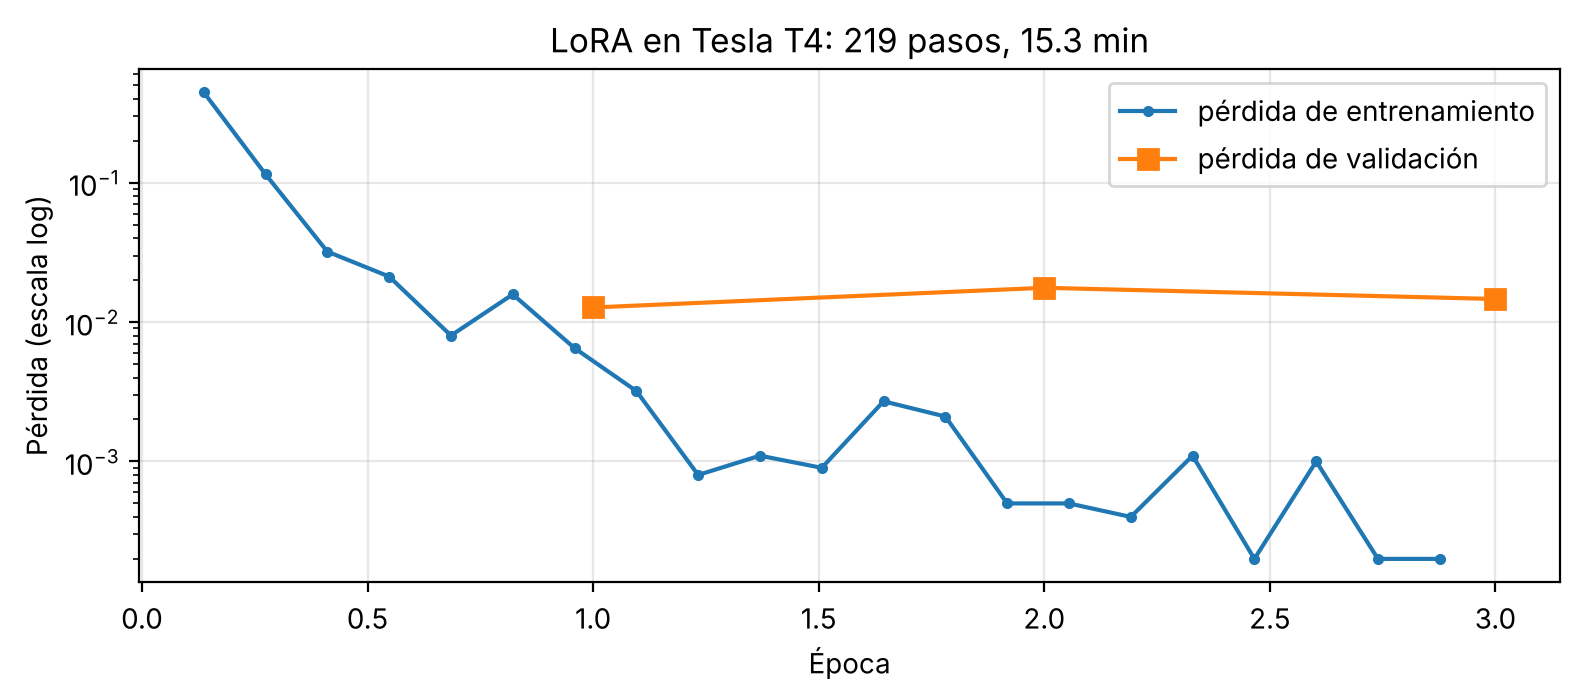

In [5]:
h = json.load(open("resultados_asistente/historial_entrenamiento.json"))
tr = [(r["epoch"], r["loss"]) for r in h if "loss" in r]
ev = [(r["epoch"], r["eval_loss"]) for r in h if "eval_loss" in r]
plt.figure(figsize=(8, 3.6))
plt.plot(*zip(*tr), "o-", ms=3, label="pérdida de entrenamiento")
plt.plot(*zip(*ev), "s-", ms=7, label="pérdida de validación")
plt.yscale("log"); plt.xlabel("Época"); plt.ylabel("Pérdida (escala log)")
plt.title(f"LoRA en {cfg['gpu']}: {cfg['pasos']} pasos, {cfg['duracion_s']/60:.1f} min")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 4. Evaluación comparativa (mismas condiciones)
Mismo *system prompt*, decodificación determinista (greedy), mismos casos: 14 reservados + 60 de prueba.

**Métricas:** JSON válido · acción correcta · **coincidencia exacta** (acción + productos y cantidades, o método/tipo).

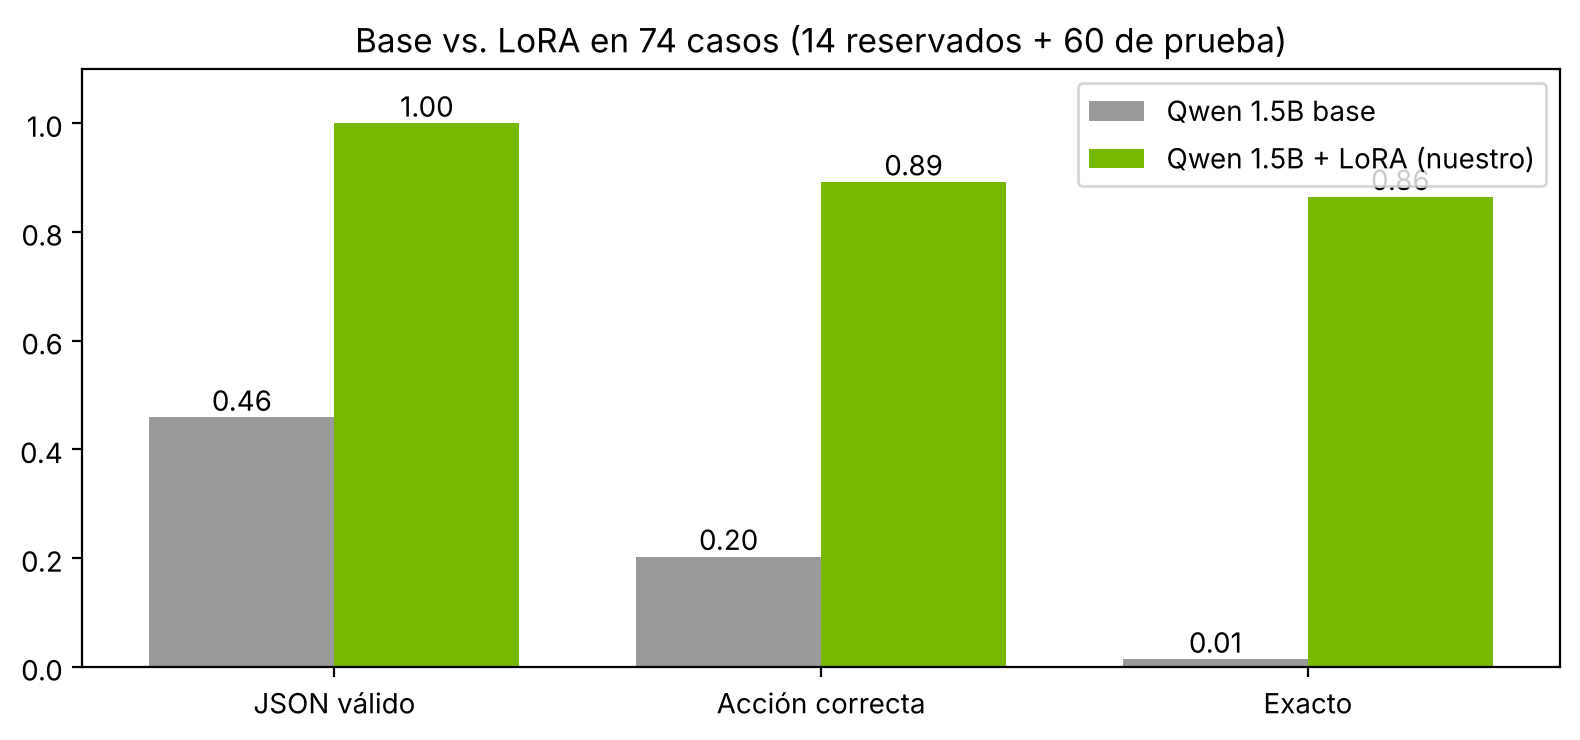

base  reservados exactos: 0/14   latencia media: 1.28 s
LoRA  reservados exactos: 13/14  latencia media: 3.17 s


In [6]:
base = json.load(open("resultados_asistente/eval_base_local.json"))
lora = json.load(open("resultados_asistente/eval_lora_local.json"))
met = ["json_valido", "accion_correcta", "exacto"]
fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(len(met)); w = .38
b1 = ax.bar(x - w/2, [base["resumen"][m] for m in met], w, label="Qwen 1.5B base", color="#999")
b2 = ax.bar(x + w/2, [lora["resumen"][m] for m in met], w, label="Qwen 1.5B + LoRA (nuestro)", color="#76b900")
ax.bar_label(b1, fmt="%.2f"); ax.bar_label(b2, fmt="%.2f")
ax.set_xticks(x); ax.set_xticklabels(["JSON válido", "Acción correcta", "Exacto"]); ax.set_ylim(0, 1.1)
ax.set_title("Base vs. LoRA en 74 casos (14 reservados + 60 de prueba)"); ax.legend(); plt.tight_layout(); plt.show()
for n, r in (("base", base["resumen"]), ("LoRA", lora["resumen"])):
    print(f"{n:5s} reservados exactos: {r['reservados_exacto']:6s} latencia media: {r['latencia_media_s']} s")

In [7]:
# Desglose por tipo de caso
def por_cat(d):
    g = collections.defaultdict(list)
    for f in d["detalle"]:
        g[f["categoria"].replace("test_", "prueba: ")].append(f["exacto"])
    return {k: (sum(v), len(v)) for k, v in g.items()}
pb, pl = por_cat(base), por_cat(lora)
print(f"{'Categoría':28s} {'Base':>8s} {'LoRA':>8s}")
for k in sorted(pl):
    print(f"{k:28s} {pb[k][0]:>3d}/{pb[k][1]:<4d} {pl[k][0]:>3d}/{pl[k][1]:<4d}")

Categoría                        Base     LoRA
fuera_de_alcance               0/2      2/2   
habitual                       0/6      6/6   
habitual_dictado               0/2      2/2   
incompleto                     0/2      1/2   
limite_confirmacion            0/2      2/2   
prueba: aclarar                0/1      0/1   
prueba: agregar                0/32    31/32  
prueba: confirmar              1/2      2/2   
prueba: consulta               0/4      2/4   
prueba: consulta_ley           0/1      1/1   
prueba: forma_pago             0/5      5/5   
prueba: fuera_de_alcance       0/2      2/2   
prueba: quitar                 0/9      6/9   
prueba: registrar_libreta      0/4      2/4   


### 4.1 Referencia: modelo de NVIDIA de 8B por API (NIM)
Medido en la laptop con `evaluar_asistente.py` contra **Nemotron 3.5 Bolt E4B** (build.nvidia.com), con los **mismos 14 casos reservados** y 30 de prueba (44 casos; la parte de prueba no es idéntica a la de arriba, por eso comparamos sobre todo los reservados).

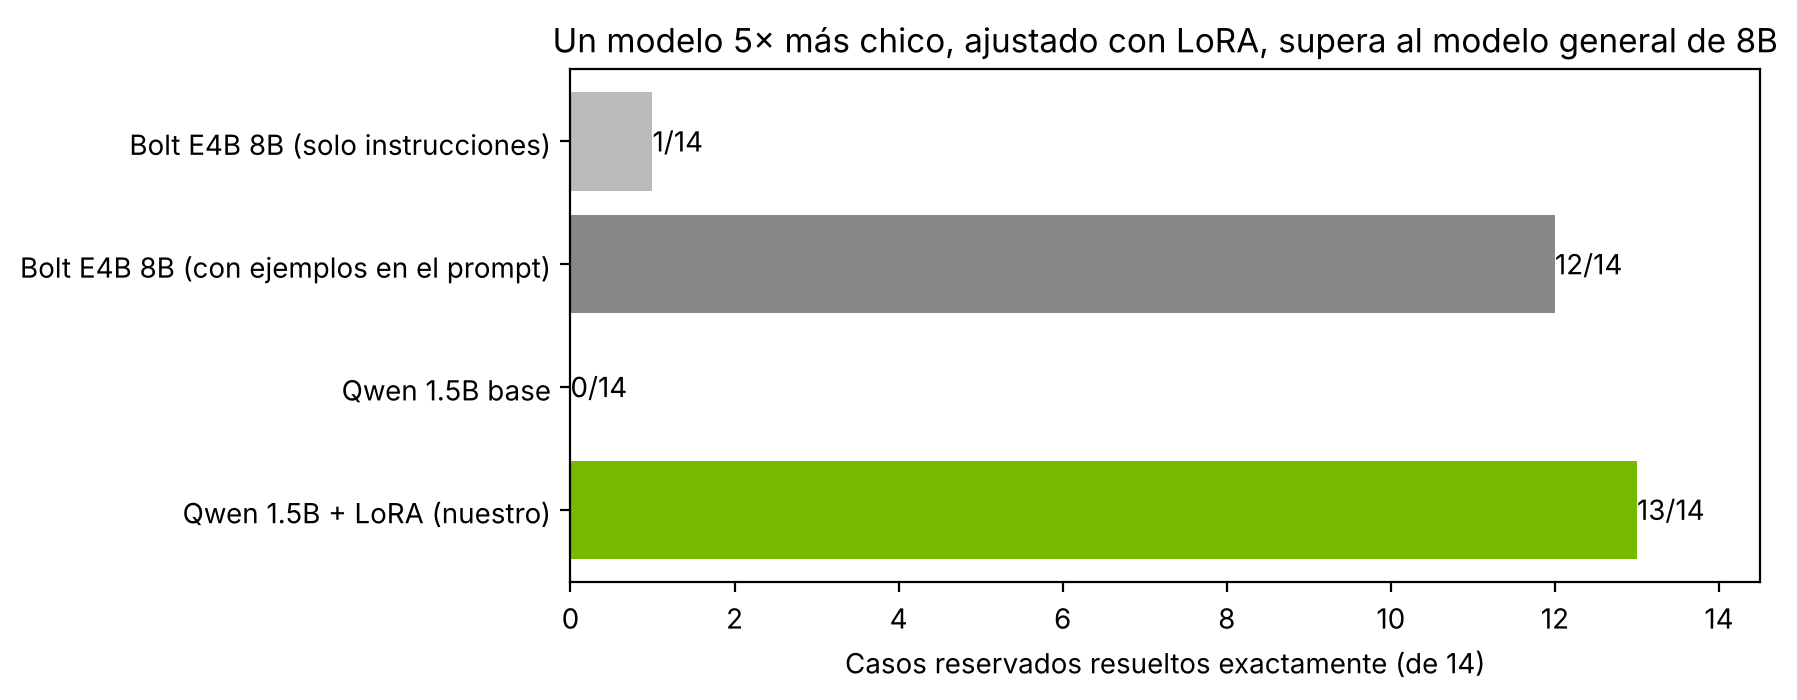

In [8]:
# Resultados medidos en la laptop (RESUMEN de evaluar_asistente.py; ver resultados_asistente/eval_bolt_*.json)
referencia = {
    "Bolt E4B 8B (solo instrucciones)": {"reservados": 1,  "exacto_44": 0.023},
    "Bolt E4B 8B (con ejemplos en el prompt)": {"reservados": 12, "exacto_44": 0.75},
    "Qwen 1.5B base": {"reservados": int(base["resumen"]["reservados_exacto"].split("/")[0])},
    "Qwen 1.5B + LoRA (nuestro)": {"reservados": int(lora["resumen"]["reservados_exacto"].split("/")[0])},
}
nombres = list(referencia); vals = [referencia[n]["reservados"] for n in nombres]
colores = ["#bbb", "#888", "#ccc", "#76b900"]
plt.figure(figsize=(9, 3.6)); b = plt.barh(nombres, vals, color=colores); plt.bar_label(b, labels=[f"{v}/14" for v in vals])
plt.xlim(0, 14.5); plt.xlabel("Casos reservados resueltos exactamente (de 14)")
plt.title("Un modelo 5× más chico, ajustado con LoRA, supera al modelo general de 8B")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

## 5. Errores y límites (interpretación honesta)
No se exige mejorar en todos los casos (bases, sección 13); documentamos dónde falla el modelo ajustado y por qué.

In [9]:
errores = [f for f in lora["detalle"] if not f["exacto"]]
print(f"Errores del modelo con LoRA: {len(errores)} de {len(lora['detalle'])}\n")
for f in errores:
    print(f"- [{f['categoria']}] {f['frase']!r}\n    esperado: {json.dumps(f['esperado'], ensure_ascii=False)[:110]}\n    obtuvo:   {f['salida'][:110]}")

Errores del modelo con LoRA: 10 de 74

- [incompleto] 'ponme tlayudas'
    esperado: {"accion": "aclarar"}
    obtuvo:   {"accion": "agregar", "productos": [{"producto": "tlayuda", "cantidad": 1}]}
- [test_aclarar] 'lo mismo que ayer'
    esperado: {"accion": "aclarar", "pregunta": "¿Qué producto y cuántos?"}
    obtuvo:   {"accion": "registrar_libreta", "fecha": "ayer"}
- [test_quitar] 'siempre no 2 varilla'
    esperado: {"accion": "quitar", "productos": [{"producto": "varilla", "cantidad": 2}]}
    obtuvo:   {"accion": "agregar", "productos": [{"producto": "varilla", "cantidad": 2}]}
- [test_consulta] 'hay pagos por confirmar?'
    esperado: {"accion": "consulta", "tipo": "pendientes"}
    obtuvo:   {"accion": "consulta", "tipo": "pagos_hoy"}
- [test_quitar] 'siempre no 20 litro de pintura'
    esperado: {"accion": "quitar", "productos": [{"producto": "pintura", "cantidad": 20}]}
    obtuvo:   {"accion": "agregar", "productos": [{"producto": "pintura", "cantidad": 20}]}
- [test_regi

**Lectura de los errores**
- **"Siempre no ..."** (quitar) sale como `agregar`: esa forma de hablar **solo existía en las plantillas de prueba**, nunca en entrenamiento. Mide la generalización; se corrige agregando esa expresión al entrenamiento.
- **"Cierra la caja"** → `confirmar`: error **seguro** (solo pide confirmación; no borra nada).
- Frases sin cantidad ("ponme tlayudas") a veces se completan con 1 en lugar de pedir aclaración. La app muestra la cantidad para que la persona la corrija antes de confirmar.
- **Latencia** en la T4 sin fusionar: 3.2 s por frase. En la app el adaptador se **fusiona** con el modelo (`merge_and_unload`) para reducirla.

## 6. Integración en la app
`servir_asistente.py` carga el modelo base + **nuestro adaptador** (hash sha256 visible en `/salud`) y expone `POST /asistente`:
1. Recibe el texto (del dictado de Android o de la caja de texto).
2. El modelo propone la acción JSON.
3. El código **valida** (acción permitida, productos del catálogo, cantidades > 0) y **calcula** precios y total.
4. Si algo no es válido → `aclarar` con un mensaje claro (bases 6e).
5. La app muestra lo entendido y la persona **revisa y confirma** (bases 6d).

In [10]:
import hashlib
h = hashlib.sha256(open("resultados_asistente/lora_adaptador/adapter_model.safetensors", "rb").read()).hexdigest()
print("sha256 del adaptador LoRA:", h)
print(json.dumps(json.load(open("resultados_asistente/lora_adaptador/adapter_config.json")), indent=1)[:600])

sha256 del adaptador LoRA: 72a3259e7285b8a8b7a0ac5c5355d7a802ff78b3f42ee19277cb1f9aef42fa0d
{
 "alpha_pattern": {},
 "auto_mapping": null,
 "base_model_name_or_path": "Qwen/Qwen2.5-1.5B-Instruct",
 "bias": "none",
 "fan_in_fan_out": false,
 "inference_mode": true,
 "init_lora_weights": true,
 "layer_replication": null,
 "layers_pattern": null,
 "layers_to_transform": null,
 "loftq_config": {},
 "lora_alpha": 32,
 "lora_dropout": 0.05,
 "megatron_config": null,
 "megatron_core": "megatron.core",
 "modules_to_save": null,
 "peft_type": "LORA",
 "r": 16,
 "rank_pattern": {},
 "revision": null,
 "target_modules": [
  "v_proj",
  "k_proj",
  "up_proj",
  "o_proj",
  "q_proj",
  "down_proj


## 7. Declaración del uso de IA
*"Para la elaboración de este trabajo se utilizó [HERRAMIENTA Y COMPAÑÍA] como apoyo en [ACTIVIDADES]. Quienes firman este trabajo han revisado y editado el contenido, verificado las fuentes y asumen plena responsabilidad por la versión final."*

**Componentes previos:** Qwen2.5-1.5B-Instruct (Apache 2.0), Hugging Face Transformers/PEFT, contenedor NVIDIA TAO 5.5 (PyTorch) como entorno de entrenamiento, NVIDIA NIM (Nemotron 3.5 Bolt E4B) como referencia. Datos 100% sintéticos generados por el equipo.